# Viewer filtered by `color_dev_frac_in`

1. **Distribution of `color_dev_frac_in`** (fraction of region pixels whose colour differs from the surrounding ring)
   and 24 crops from the lowest to the highest value.
2. **Filter**: keep only the images with `color_dev_frac_in < THRESHOLD` (default 0.01). Images without a value
   (no region, or region too small) are dropped unless `INCLUDE_NAN = True`.
3. **For every other metric**, on the remaining images only: the `N` crops with the **lowest** values and the `N`
   with the **highest** values (numerically: for `brisque` and `niqe` lower = better). No mask contour is drawn on the crops.

All figures (PNG) and the list of the selected images (`extremes.csv`) are saved in `SAVE_DIR`.

In [13]:
from pathlib import Path
import shutil
import sys

# ---- settings ----------------------------------------------------------------------------------
SCRIPTS = Path(".")                                   # folder containing common.py
OUT = Path("/var/home/da/Downloads/results-lamarr")       # --out folder of the scripts
SAVE_DIR = OUT / "viewer"                             # where figures and csv are saved
SAVE = True                                           # False = display only
COPY_CROPS = False                                    # True = also copy the selected crops to SAVE_DIR/<metric>/{lowest,highest}/
DPI = 150

FILTER_METRIC = "color_dev_frac_in"
THRESHOLD = 0.02                                       # keep values < THRESHOLD
INCLUDE_NAN = False                                   # True = also keep images without FILTER_METRIC
KIND = "all"                                          # face | mask | full | all
N = 6                                                 # images per extreme
METRICS_TO_SHOW = ["topiq_nr-face", "musiq", "clipiqa", "brisque", "niqe", "maniqa", "clip_score", "mps_score"]
LOWER_IS_BETTER = {"brisque", "niqe"}                 # only used to remind it in the title

sys.path.insert(0, str(SCRIPTS.resolve()))
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from common import load_merged

df = load_merged(OUT)
if KIND != "all":
    df = df[df["crop_kind"] == KIND]
print(f"{len(df)} images, crop_kind: {df['crop_kind'].value_counts().to_dict()}")
print("available metrics:", [m for m in [FILTER_METRIC] + METRICS_TO_SHOW if m in df and df[m].notna().any()])
print("missing or empty metrics:", [m for m in [FILTER_METRIC] + METRICS_TO_SHOW if m not in df or not df[m].notna().any()])

5370 images, crop_kind: {'face': 4940, 'mask': 430}
available metrics: ['color_dev_frac_in', 'topiq_nr-face', 'musiq', 'clipiqa', 'brisque', 'niqe', 'maniqa', 'clip_score', 'mps_score']
missing or empty metrics: []


## Functions

In [14]:
SELECTED = []          # list of the selected images, saved to extremes.csv


def load_crop(row):
    img = cv2.imread(str(OUT / row["crop_file"]), cv2.IMREAD_COLOR)
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def short_name(f):
    return Path(f).stem.split("_inpainted")[0][:28]


def save_fig(fig, name):
    if SAVE:
        SAVE_DIR.mkdir(parents=True, exist_ok=True)
        p = SAVE_DIR / f"{name}.png"
        fig.savefig(p, dpi=DPI, bbox_inches="tight")
        print("saved", p)


def draw_tile(ax, row, metric):
    img = load_crop(row)
    if img is not None:
        ax.imshow(img)
    flags = row.get("flags") if isinstance(row.get("flags"), str) else ""
    title = f"{row[metric]:.4g}\n{short_name(row['file'])}"
    if flags:
        title += f"\n{flags}"
    ax.set_title(title, fontsize=7.5, color="#b00020" if flags else "black")
    ax.set_xticks([]); ax.set_yticks([])


def histogram(ax, values, marks, title, thr=None):
    ax.hist(values, bins=60, color="#9aa5b1")
    for v in marks:
        ax.axvline(v, color="#d1495b", lw=0.8, alpha=0.8)
    if thr is not None:
        ax.axvline(thr, color="black", lw=1.5, ls="--")
    ax.set_title(title, fontsize=11)
    ax.tick_params(labelsize=8)
    ax.set_yticks([])


def show_quantiles(d, metric, n=24, cols=6, tile=2.6, thr=None, name=None):
    """n images spread evenly from the lowest to the highest value of the metric."""
    d = d[d[metric].notna()].sort_values(metric, kind="mergesort").reset_index(drop=True)
    if d.empty:
        print(f"No image with {metric}")
        return
    pos = np.unique(np.round(np.linspace(0, len(d) - 1, min(n, len(d)))).astype(int))
    sel = d.iloc[pos]
    rows = int(np.ceil(len(sel) / cols))
    fig = plt.figure(figsize=(cols * tile, 1.6 + rows * (tile + 0.5)))
    gs = gridspec.GridSpec(rows + 1, cols, height_ratios=[1.6 / tile] + [1] * rows, hspace=0.45, wspace=0.05)
    histogram(fig.add_subplot(gs[0, :]), d[metric], sel[metric],
              f"{metric}  ({len(d)} images, ascending)" + (f"  -  dashed line: threshold {thr}" if thr is not None else ""), thr)
    for i, (_, r) in enumerate(sel.iterrows()):
        draw_tile(fig.add_subplot(gs[1 + i // cols, i % cols]), r, metric)
    save_fig(fig, name or f"{metric}_quantiles")
    plt.show()


def extremes(d, metric, n=N):
    """(n lowest, n highest from the top down, number of valid images). Never overlapping."""
    d = d[d[metric].notna()].sort_values(metric, kind="mergesort")
    k = min(n, len(d) // 2)
    return d.head(k), d.tail(k).iloc[::-1], len(d)


def show_extremes(d, metric, n=N, tile=2.6):
    low, high, tot = extremes(d, metric, n)
    if len(low) == 0:
        print(f"{metric}: too few valid images ({tot}), skipped")
        return
    k = len(low)
    fig = plt.figure(figsize=(max(k, 3) * tile, 1.6 + 2 * (tile + 0.6)))
    gs = gridspec.GridSpec(3, k, height_ratios=[1.6 / tile, 1, 1], hspace=0.55, wspace=0.05)
    better = "  -  lower = better" if metric in LOWER_IS_BETTER else ""
    histogram(fig.add_subplot(gs[0, :]), d[metric].dropna(), list(low[metric]) + list(high[metric]),
              f"{metric}  ({tot} filtered images){better}")
    for row_i, (label, part) in enumerate((("lowest values", low), ("highest values", high)), start=1):
        for j, (_, r) in enumerate(part.iterrows()):
            ax = fig.add_subplot(gs[row_i, j])
            draw_tile(ax, r, metric)
            if j == 0:
                ax.set_ylabel(label, fontsize=9)
            SELECTED.append({"metric": metric, "extreme": "lowest" if row_i == 1 else "highest", "rank": j + 1,
                             "value": float(r[metric]), "file": r["file"], "crop_file": r["crop_file"],
                             FILTER_METRIC: r.get(FILTER_METRIC)})
    save_fig(fig, f"{metric}_extremes")
    plt.show()
    if SAVE and COPY_CROPS:
        for tag, part in (("lowest", low), ("highest", high)):
            dst = SAVE_DIR / metric / tag
            dst.mkdir(parents=True, exist_ok=True)
            for j, (_, r) in enumerate(part.iterrows(), 1):
                shutil.copy(OUT / r["crop_file"], dst / f"{j:02d}_{r[metric]:.4g}_{Path(r['crop_file']).name}")

## 1. `color_dev_frac_in`: distribution and crops from lowest to highest

saved /var/home/da/Downloads/results-lamarr/viewer/color_dev_frac_in_quantiles.png


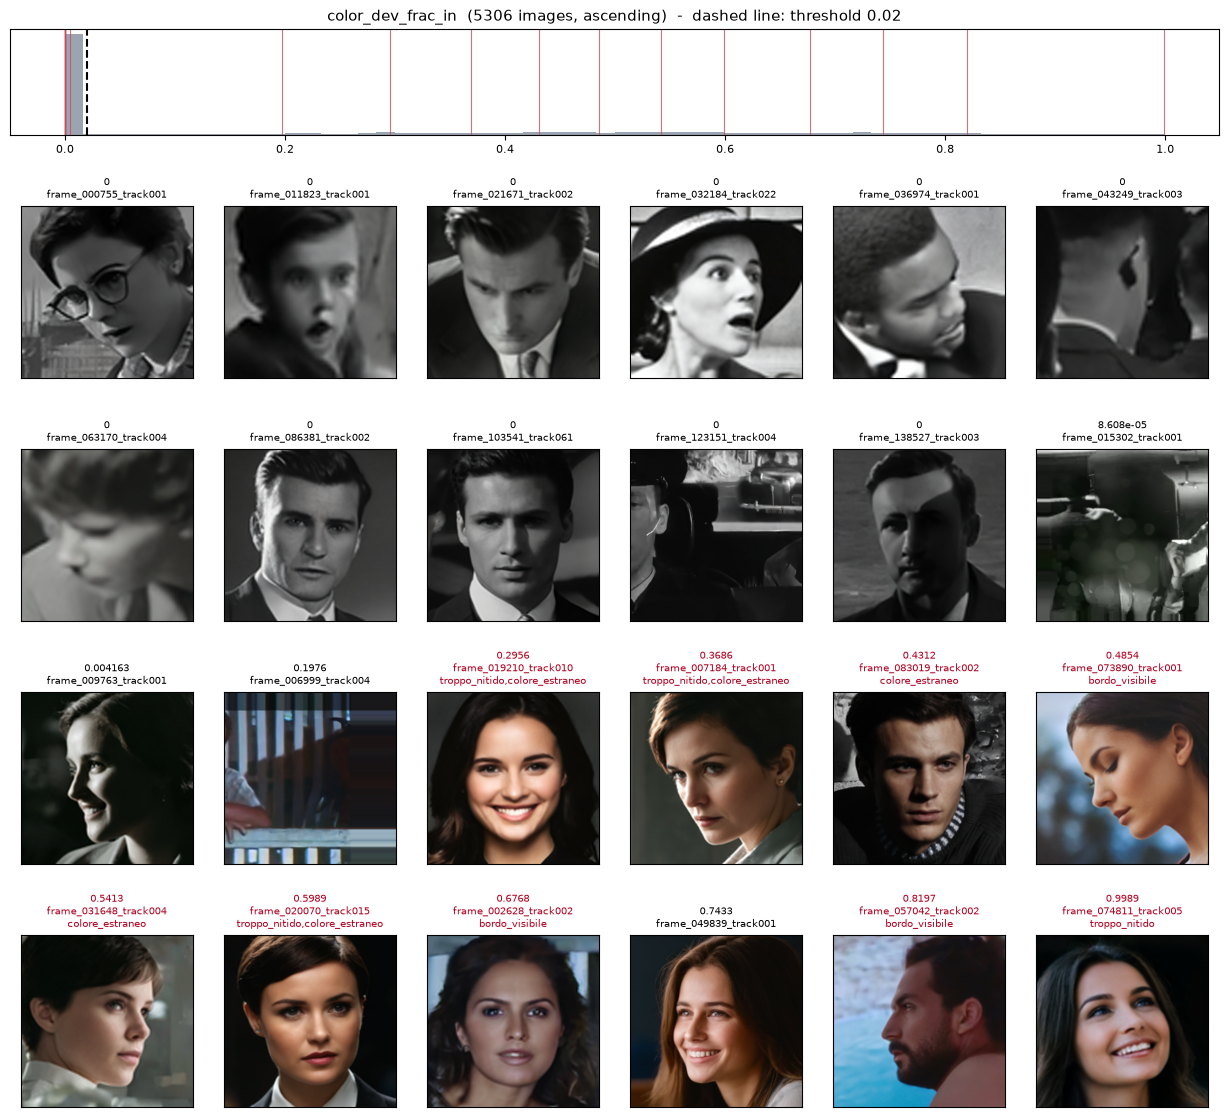

color_dev_frac_in: 5306 values, 64 missing
below 0.02: 2825   (53.2% of the available values)
median 0.0004   p90 0.7208   max 0.9989


In [15]:
show_quantiles(df, FILTER_METRIC, n=24, thr=THRESHOLD)
v = df[FILTER_METRIC]
print(f"{FILTER_METRIC}: {v.notna().sum()} values, {v.isna().sum()} missing")
print(f"below {THRESHOLD}: {(v < THRESHOLD).sum()}   ({100 * (v < THRESHOLD).sum() / max(v.notna().sum(), 1):.1f}% of the available values)")
print(f"median {v.median():.4f}   p90 {v.quantile(.9):.4f}   max {v.max():.4f}")

## 2. Filter

In [16]:
keep = df[FILTER_METRIC] < THRESHOLD
if INCLUDE_NAN:
    keep |= df[FILTER_METRIC].isna()
dff = df[keep].copy()
print(f"kept {len(dff)} of {len(df)} images ({FILTER_METRIC} < {THRESHOLD}"
      f"{', plus those without a value' if INCLUDE_NAN else ''}); dropped {len(df) - len(dff)}")
print("\nvalid values per metric after the filter:")
print(pd.Series({m: int(dff[m].notna().sum()) if m in dff else 0 for m in METRICS_TO_SHOW}).to_string())

kept 2825 of 5370 images (color_dev_frac_in < 0.02); dropped 2545

valid values per metric after the filter:
topiq_nr-face    2363
musiq            2825
clipiqa          2825
brisque          2825
niqe             2825
maniqa           2825
clip_score       2825
mps_score        2825


## 3. The N lowest and N highest images for each metric

saved /var/home/da/Downloads/results-lamarr/viewer/topiq_nr-face_extremes.png


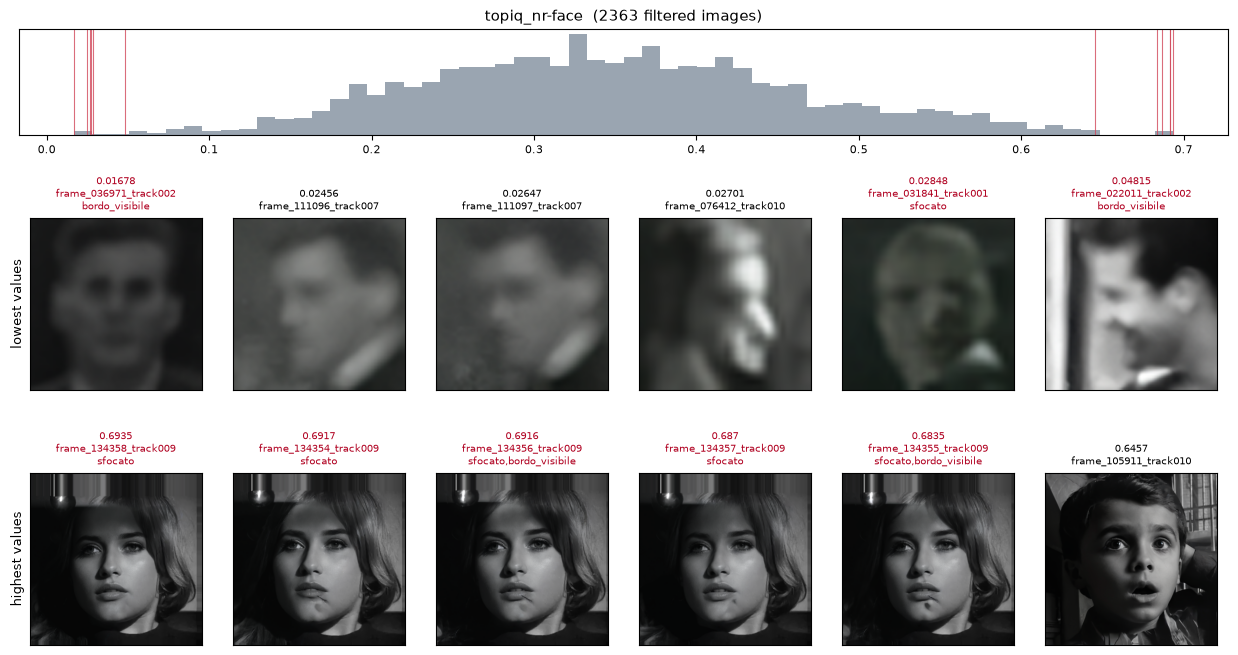

saved /var/home/da/Downloads/results-lamarr/viewer/musiq_extremes.png


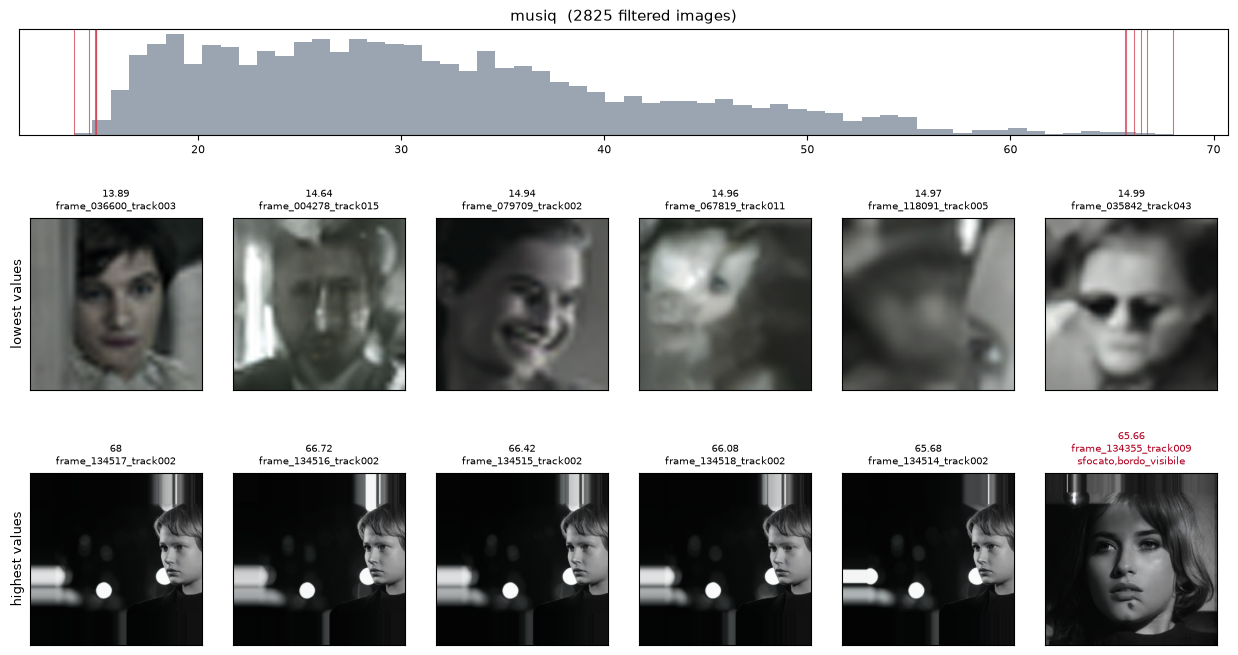

saved /var/home/da/Downloads/results-lamarr/viewer/clipiqa_extremes.png


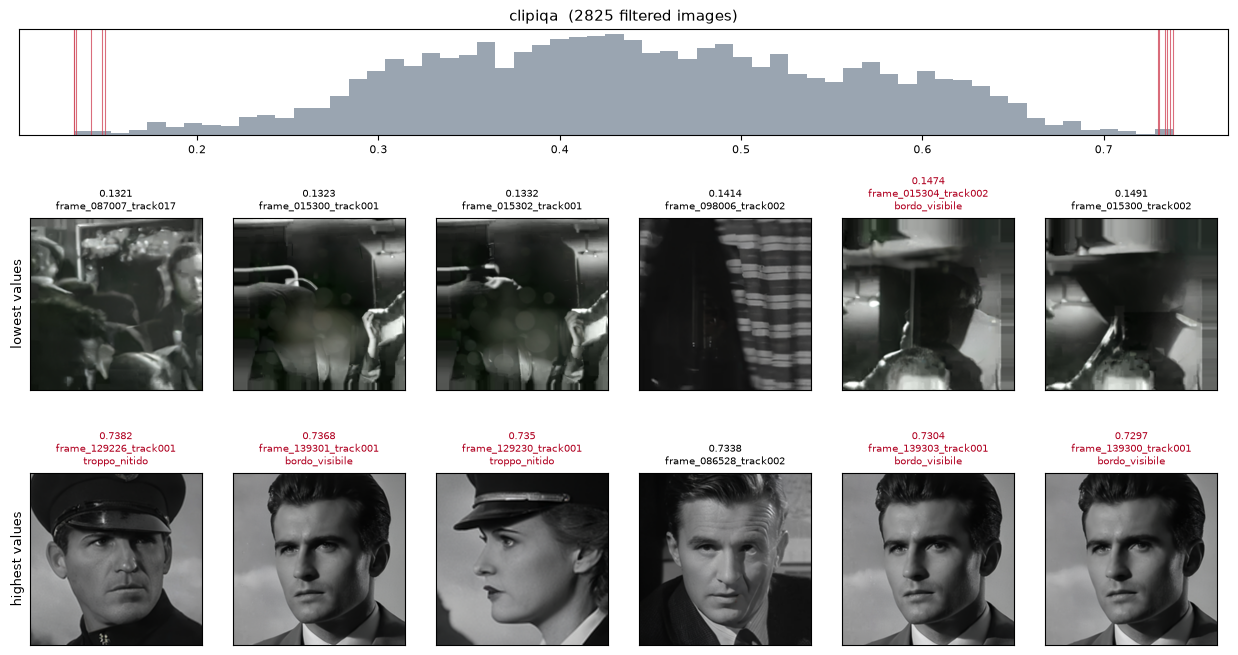

saved /var/home/da/Downloads/results-lamarr/viewer/brisque_extremes.png


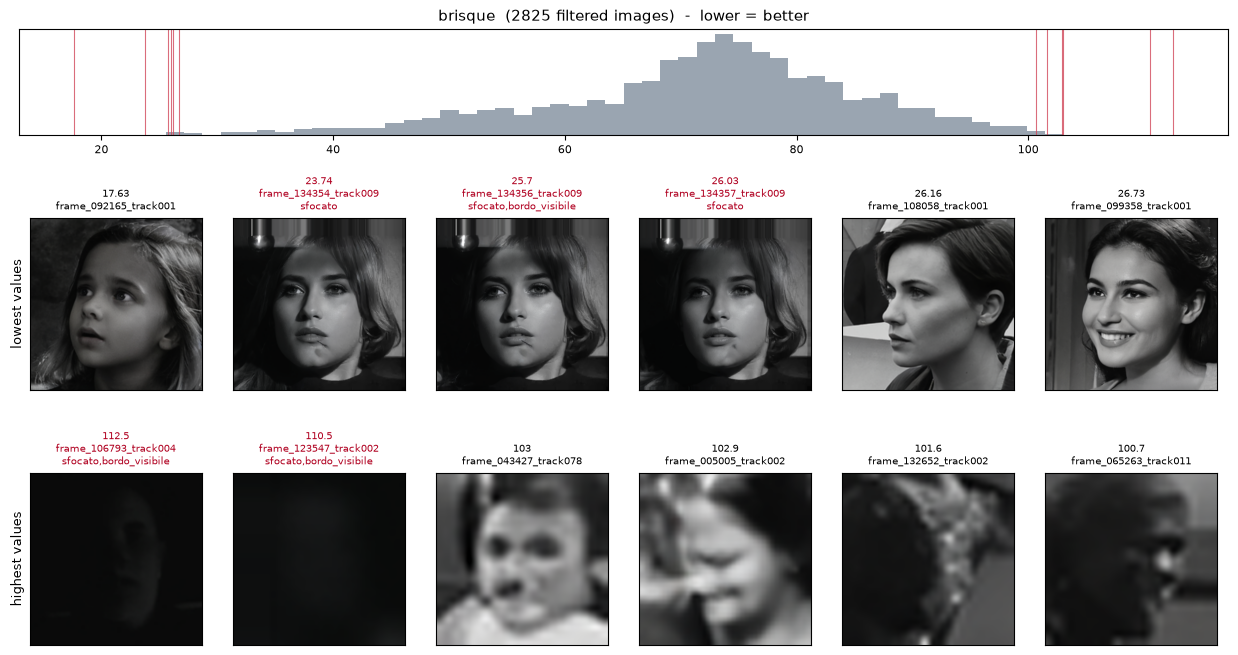

saved /var/home/da/Downloads/results-lamarr/viewer/niqe_extremes.png


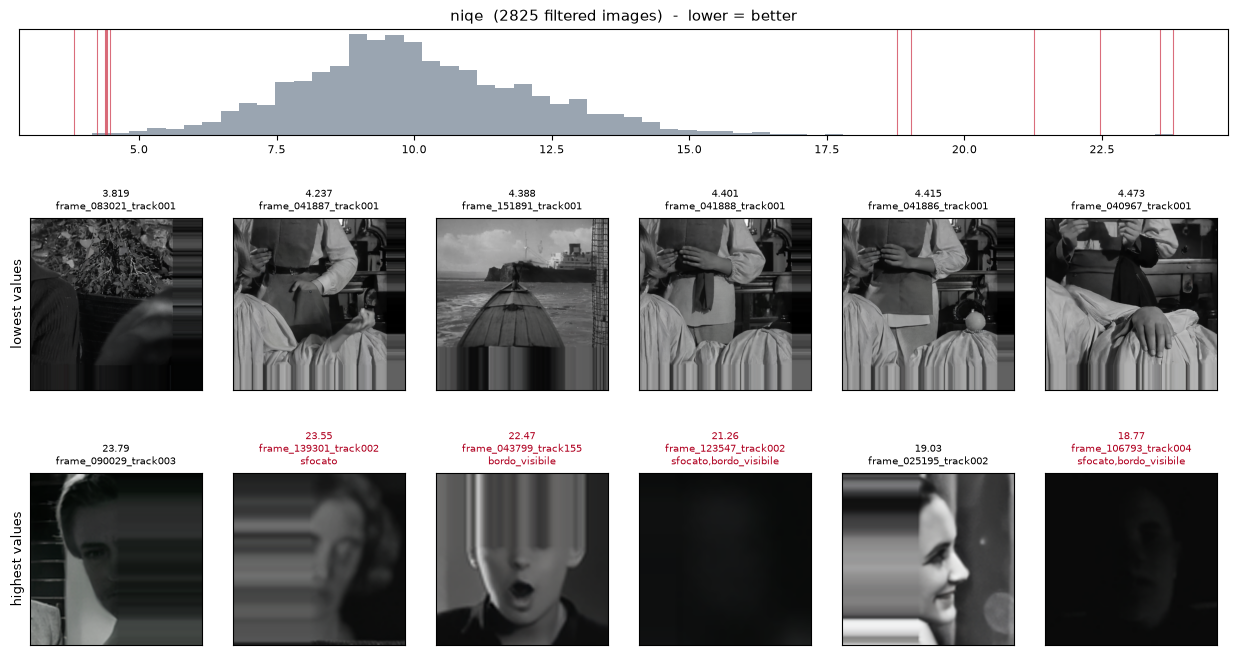

saved /var/home/da/Downloads/results-lamarr/viewer/maniqa_extremes.png


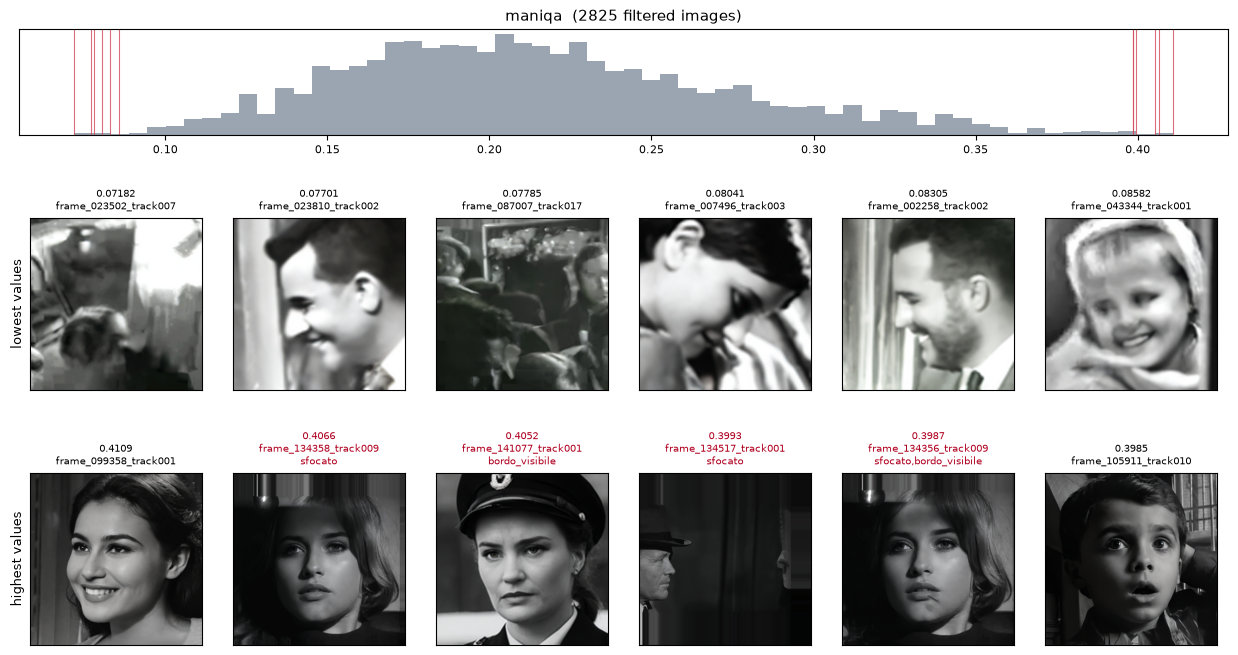

saved /var/home/da/Downloads/results-lamarr/viewer/clip_score_extremes.png


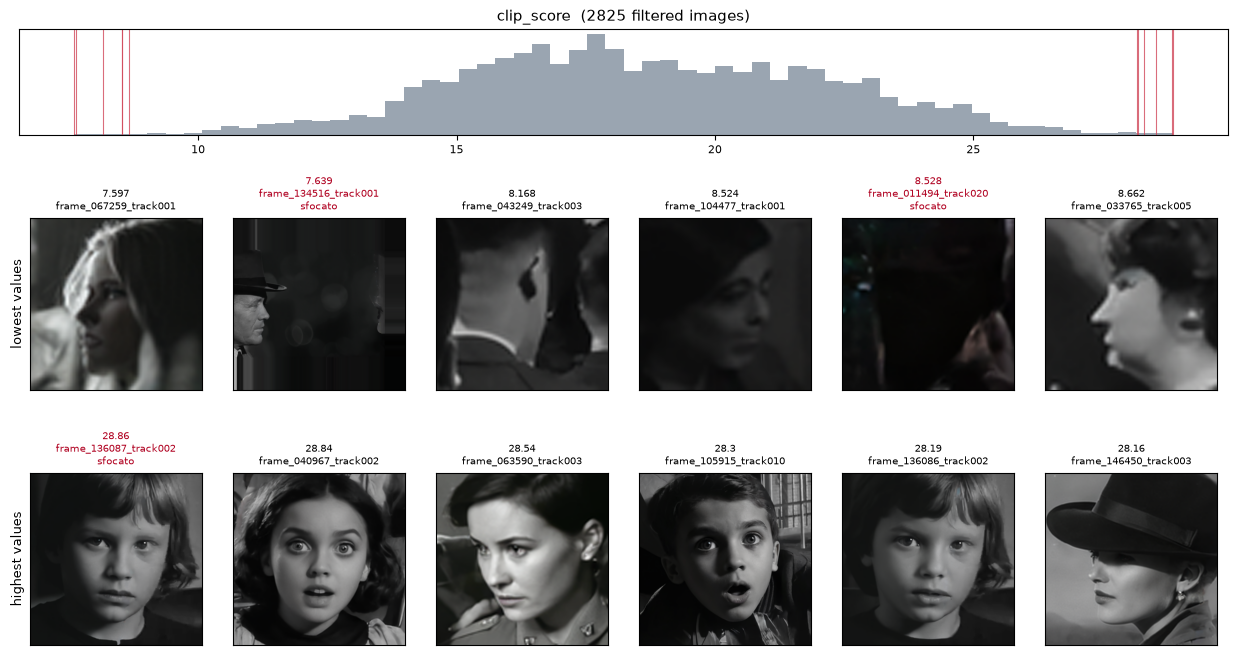

saved /var/home/da/Downloads/results-lamarr/viewer/mps_score_extremes.png


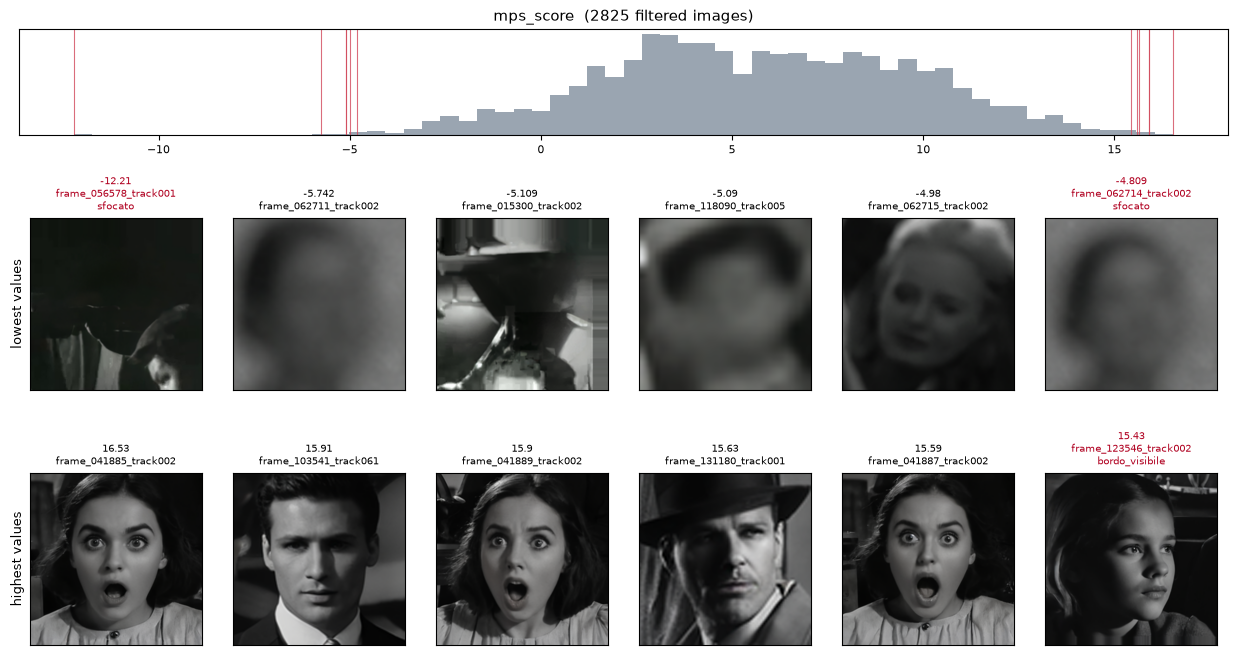

In [17]:
for m in METRICS_TO_SHOW:
    if m not in dff or not dff[m].notna().any():
        print(f"{m}: missing or empty, skipped")
        continue
    show_extremes(dff, m, N)

## 4. Save the list of selected images

In [ ]:
sel = pd.DataFrame(SELECTED)
if SAVE and not sel.empty:
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    sel.to_csv(SAVE_DIR / "extremes.csv", index=False)
    print("saved", SAVE_DIR / "extremes.csv")
sel